# Multimodal

Multimodal là dùng nhiều loại dữ liệu cùng lúc, như ảnh, chữ và âm thanh. Ví dụ một thông báo gồm ảnh phòng học, dòng chữ “như trong ảnh” và một đoạn ghi âm; chỉ đọc một nguồn thì không hiểu đủ. Bài này học các cách ghép thông tin từ nhiều nguồn, cách bảo đảm các nguồn được ghép đúng cùng một mẫu, và cách kiểm thêm một nguồn có thật sự làm dự đoán tốt hơn không.

> **Mục tiêu**
>
> - Ghép dữ liệu nhiều nguồn đúng ID và đúng thời gian.
> - Phân biệt early fusion, late fusion và gating; xử lý khi thiếu một nguồn.
> - Đo đóng góp của từng nguồn bằng ablation.
> - Hiểu cách model ảnh–chữ (VLM) đọc ảnh.

## Một mẫu có nhiều modality, nhưng chỉ một ID

Modality là loại tín hiệu: ảnh, văn bản, âm thanh, video hoặc dữ liệu cảm biến. Mô hình đa phương thức (multimodal) nhận hoặc sinh nhiều loại tín hiệu như thế; GPT-4V chẳng hạn đọc được cả ảnh lẫn chữ để trả lời câu hỏi về ảnh. Một sample có thể chứa nhiều modality cùng mô tả một sự việc.

Điều đầu tiên cần đúng là quan hệ cặp: ảnh nào đi với câu nào, audio nào thuộc clip nào. Join theo ID có thể kiểm được; ghép theo thứ tự của hai thư mục là một giả định rất dễ sai.

Với dữ liệu video và audio, alignment còn là thời gian: phụ đề ở giây 4 không tự gắn với khung hình giây 0. Mỗi luồng có nhịp riêng: video thường 25 hoặc 30 khung mỗi giây, còn đặc trưng âm với hop 10 ms cho 100 frame mỗi giây. Muốn ghép, đổi chỉ số về giây trước rồi mới sang luồng kia: frame âm thứ $k$ bắt đầu ở $t=0.01k$ giây và rơi vào khung hình $\lfloor 25t\rfloor$ của video 25 khung mỗi giây.

Một người nói có nhiều clip hoặc một sự kiện có nhiều ảnh thì group split phải giữ đúng đơn vị độc lập. Chia từng modality riêng rồi mới ghép dễ làm train nhìn thấy ảnh của một sample mà validation dùng chữ của chính sample đó.

Ta ký hiệu embedding ảnh $\mathbf v\in\R^{d_v}$, chữ $\mathbf t\in\R^{d_t}$, âm $\mathbf a\in\R^{d_a}$. Chữ đậm là vector, $d_v,d_t,d_a$ là số chiều chứ không phải số mẫu. Trong batch, các mảng tương ứng có shape `(B,d_v)`, `(B,d_t)`, `(B,d_a)`. Những embedding có thể đến từ model pretrained được phép dùng, hoặc đặc trưng đơn giản; phải ghi rõ nguồn. [Khảo sát Multimodal Machine Learning](https://arxiv.org/abs/1705.09406) là tài liệu để đặt fusion cạnh alignment và biểu diễn.



**Hỏi nhanh.** Ảnh và caption nằm ở hai CSV được sắp xếp khác nhau, và cả hai đều có cột `id`. Ghép thế nào cho đáng tin nhất?

- A. Ghép hàng thứ $i$ với hàng thứ $i$, vì hai file có cùng số dòng
- B. Sắp cả hai file theo `id`, rồi ghép theo thứ tự hàng
- C. Join theo `id`, rồi đếm số ID bị trùng và bị thiếu
- D. Chỉ dùng ảnh, để khỏi phải kiểm quan hệ cặp

<details><summary>Đáp án</summary>

C. Join theo `id`, rồi đếm số ID bị trùng và bị thiếu

Join theo khóa nối đúng ảnh với caption của nó, còn bước đếm bắt được ID thiếu hoặc lặp trước khi train. Cùng số dòng chưa có nghĩa là cùng thứ tự. Sắp theo `id` rồi ghép theo hàng chỉ đúng khi hai file có đúng cùng một tập ID. Thiếu một caption là mọi hàng sau lệch đi một bậc, mà tensor vẫn đúng shape. Bỏ caption là né lỗi bằng cách bỏ luôn một nguồn thông tin.

</details>



**Hỏi nhanh.** Video có 25 khung mỗi giây, còn đặc trưng âm có hop 10 ms. Tiếng còi bắt đầu ở frame âm 430, đếm từ 0. Khung hình nào chứa thời điểm đó?

- A. Khung 17
- B. Khung 107
- C. Khung 430
- D. Khung 1075

<details><summary>Đáp án</summary>

B. Khung 107

Frame âm 430 bắt đầu ở $430\times 0.01 = 4.3$ giây. $4.3\times 25 = 107.5$, nên thời điểm này nằm trong khung 107. 430 là dùng thẳng chỉ số của luồng âm cho video. 17 là $\lfloor 430/25\rfloor$, tức chia cho số khung mỗi giây thay vì đổi chỉ số âm ra giây rồi mới nhân. 1075 là lấy hop 0.1 giây thay vì 0.01 giây. Lệch vài khung thôi đã đủ để lời nói đi với khuôn mặt của người khác.

</details>



## Early fusion: cho head đọc các đặc trưng cùng lúc

Early fusion có thể ghép vector thành

$$\mathbf z=[\mathbf v;\mathbf t;\mathbf a]\in\R^{d_v+d_t+d_a}.$$

Dấu `;` nghĩa là nối theo chiều đặc trưng, không cộng từng tọa độ. Với `(B,32)` và `(B,16)`, concatenation cho `(B,48)`. Head nhận cả hai nguồn, nhưng học được tương tác giữa chúng hay không là do kiến trúc head. Một linear head tách được theo từng khối của $\mathbf w$:

$$\mathbf w^\top\mathbf z+b=\mathbf w_v^\top\mathbf v+\mathbf w_t^\top\mathbf t+\mathbf w_a^\top\mathbf a+b,$$

tức một tổng các điểm, mỗi điểm chỉ đọc một nguồn. Nó không biểu diễn được quy tắc kiểu “caption ‘phòng yên tĩnh’ chỉ đáng tin khi audio không có tiếng ồn”: ở đó ý nghĩa của nguồn này phụ thuộc nguồn kia. MLP, hoặc đặc trưng tích chéo như $v_it_j$, biểu diễn được những tương tác ấy.

Để thấy giới hạn này, ta dùng hai tín hiệu nhị phân tổng hợp đóng vai hai modality. Quy tắc nhãn là XOR: bằng 1 nếu hai tín hiệu khác nhau. Biết từng tín hiệu riêng không đủ, và một tổng hai điểm riêng cũng không đủ; cần một hàm phi tuyến của cả hai (như XOR ở bài 3.2).

Ta thêm nhiễu nhỏ, chia dữ liệu trước khi fit scaler và model và so hai head trên cùng validation.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

rng = np.random.default_rng(74)
binary_signals = rng.integers(0, 2, size=(400, 2))
labels = np.logical_xor(binary_signals[:, 0], binary_signals[:, 1]).astype(int)
features = binary_signals + rng.normal(0, 0.04, binary_signals.shape)
train_indices, valid_indices = train_test_split(
    np.arange(400), test_size=0.25, random_state=7, stratify=labels
)
linear_fusion = make_pipeline(StandardScaler(), LogisticRegression(max_iter=300))
nonlinear_fusion = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(8,), activation="tanh", solver="lbfgs", max_iter=1000, random_state=7),
)
for name, model in [("linear", linear_fusion), ("MLP", nonlinear_fusion)]:
    model.fit(features[train_indices], labels[train_indices])
    predictions = model.predict(features[valid_indices])
    print(f"{name}: accuracy = {accuracy_score(labels[valid_indices], predictions):.3f}")
print(features.shape)

linear: accuracy = 0.470
MLP: accuracy = 1.000
(400, 2)


Nhìn chênh lệch giữa hai head: early fusion chỉ **cung cấp** thông tin chung; kiến trúc quyết định có học được tương tác cần thiết không.

Hai lớp XOR nằm ở hai cặp góc đối diện nên một đường thẳng không tách hết được: logistic regression chỉ đạt 0.470 trên 100 mẫu validation, ngang đoán ngẫu nhiên, còn MLP 8 nút ẩn đạt 1.000. Với embedding thật, tương tác hiếm khi gọn như XOR; so linear head với một MLP nhỏ trên cùng validation là cách rẻ để biết có đáng thêm phi tuyến hay không.



Khi các nhánh có thang đo khác nhau, chuẩn hóa bằng train hoặc dùng normalization phù hợp từng encoder. Vector âm có norm lớn gấp trăm lần không tự nói rằng âm quan trọng gấp trăm lần. Nếu fine-tune cả hai encoder, cần kiểm learning rate và gradient từng nhánh; head có thể bỏ qua một nguồn nếu nguồn kia là đường tắt dễ học hơn.

**Hỏi nhanh.** Với hai tín hiệu XOR ở trên, một đội giữ logistic regression, nhưng đưa vào $[x_1;\,x_2;\,x_1x_2]$ thay cho $[x_1;\,x_2]$. Kết quả thế nào?

- A. Tách được, vì nhãn bằng $x_1 + x_2 - 2x_1x_2$
- B. Vẫn không tách được, vì head vẫn tuyến tính
- C. Tách được, nhưng phải thêm cả $x_1^2$ và $x_2^2$
- D. Không đổi gì, vì $x_1x_2$ suy ra được từ $x_1$, $x_2$

<details><summary>Đáp án</summary>

A. Tách được, vì nhãn bằng $x_1 + x_2 - 2x_1x_2$

Với $x_1, x_2 \in \{0, 1\}$, biểu thức $x_1 + x_2 - 2x_1x_2$ cho 0, 1, 1, 0, đúng bằng XOR, và nó tuyến tính theo ba đặc trưng mới. Đặc trưng tích là phần tương tác được viết sẵn cho head, nên head tuyến tính trên đặc trưng mới vẽ được biên. $x_1x_2$ đúng là tính được từ $x_1$ và $x_2$, nhưng bằng phép nhân, mà linear head không tự nhân hai đầu vào với nhau. Với giá trị nhị phân, $x_1^2 = x_1$, nên bình phương không thêm gì.

</details>

## Late fusion: gộp xác suất cùng một mục tiêu

Late fusion để mỗi nhánh trả xác suất cho cùng các lớp, rồi gộp:

$$\mathbf p=\alpha\mathbf p^{(v)}+(1-\alpha)\mathbf p^{(t)},\qquad 0\leq\alpha\leq1.$$

$\alpha$ là trọng số nhánh ảnh. Các cột phải dùng cùng `class_to_index`; trung bình cột “chuông” của nhánh âm với cột “xe” của nhánh chữ không phải ensemble hợp lệ. Trung bình logits và trung bình probabilities cũng là hai thuật toán khác nhau.

Nhánh quá tự tin có thể lấn át nhánh tốt hơn; calibration và trọng số phải chọn trên validation, không suy từ số tham số.

Với hai head tuyến tính, cộng logit có trọng số cho cùng dạng hàm $\mathbf w_v^\top\mathbf v+\mathbf w_t^\top\mathbf t+b$ như early fusion với linear head; chỗ khác là trọng số được học riêng từng nhánh hay học chung. Muốn mức tin vào mỗi nguồn đổi theo từng mẫu, cho $\alpha$ là hàm của input, $\alpha=\sigma\big(g(\mathbf v,\mathbf t)\big)$ với $g$ là một mạng nhỏ học cùng hai nhánh. Cách gộp này gọi là gating.

Để tính tay được, ta dùng bảng xác suất đặt sẵn cho tám mẫu. Mỗi giá trị là xác suất lớp 1 của một nhánh; xác suất lớp 0 bằng $1-p$. Hai nhánh được đặt sai ở những mẫu khác nhau (lỗi bổ sung), đúng tình huống fusion có ích nhất.

In [ ]:
toy_labels = np.array([1, 1, 1, 1, 0, 0, 0, 0])
image_probability = np.array([0.90, 0.80, 0.40, 0.30, 0.10, 0.20, 0.60, 0.70])
text_probability = np.array([0.40, 0.35, 0.85, 0.90, 0.55, 0.65, 0.25, 0.20])
fused_probability = (image_probability + text_probability) / 2
for name, probability in [
    ("image", image_probability),
    ("text", text_probability),
    ("fusion", fused_probability),
]:
    prediction = (probability >= 0.5).astype(int)
    print(f"{name}: accuracy = {accuracy_score(toy_labels, prediction):.3f}")
print(fused_probability.round(3))

image: accuracy = 0.500
text: accuracy = 0.500
fusion: accuracy = 1.000
[0.65  0.575 0.625 0.6   0.325 0.425 0.425 0.45 ]


Ví dụ tính tay: mẫu thứ ba có nhãn 1, nhánh ảnh cho 0.40 nên sai, nhánh chữ cho 0.85; gộp bằng $(0.40+0.85)/2=0.625$, vượt ngưỡng 0.5 nên đúng. Nhưng nếu một nhánh tự tin sai 0.01 còn nhánh kia đúng nhẹ 0.55, trung bình 0.28 lại sai.

Fusion có lợi khi hai nhánh sai ở những mẫu khác nhau và không nhánh nào tự tin sai; khi hai nhánh cùng sai một mẫu, gộp không cứu được. Vì vậy đóng góp của mỗi nguồn phải đo trên validation thật, như mục sau.



**Hỏi nhanh.** Trên validation, nhánh ảnh đáng tin khi ảnh đủ sáng, còn với ảnh tối thì nhánh chữ đúng hơn. Cách gộp nào biểu diễn được quy tắc này?

- A. Late fusion với một $\alpha$ cố định, dò trên validation
- B. Early fusion $[\mathbf v;\mathbf t]$ với một linear head
- C. Gating, tức một mạng nhỏ cho ra $\alpha$ riêng cho từng mẫu
- D. Cộng logit hai nhánh, sau khi nhân nhánh ảnh với 2

<details><summary>Đáp án</summary>

C. Gating, tức một mạng nhỏ cho ra $\alpha$ riêng cho từng mẫu

Quy tắc này cần mức tin vào ảnh phụ thuộc chính ảnh, tức là một tương tác. Gating học $\alpha$ theo input, chẳng hạn $g$ đọc độ sáng từ $\mathbf v$. Một $\alpha$ cố định cho mọi mẫu cùng một mức tin, dù được dò kỹ đến đâu. Linear head trên $[\mathbf v;\mathbf t]$ chỉ là tổng của hai điểm riêng, nên cũng không đổi mức tin theo độ sáng. Nhân nhánh ảnh với 2 chỉ là một trọng số cố định khác.

</details>

## Ablation: nguồn nào giúp, nhờ nội dung hay nhờ đường tắt?

Ablation bỏ hoặc thay một thành phần, giữ các điều kiện khác, rồi đo lại. Trong bảng vừa rồi, ta đã đo ảnh riêng, chữ riêng và ghép. Tiếp theo cố ý ghép sai caption bằng cách dịch vòng bốn vị trí. Số mẫu và shape vẫn đúng, nhưng ý nghĩa cặp đã sai:

In [ ]:
wrongly_paired_text = np.roll(
    text_probability, 4
)
wrong_fusion = (
    image_probability + wrongly_paired_text
) / 2
print(f"sai cặp: accuracy = {accuracy_score(toy_labels, wrong_fusion >= 0.5):.3f}")

sai cặp: accuracy = 0.500




Điểm giảm trong bảng minh họa cho biết quan hệ cặp là phần của bài toán. Với dữ liệu thật, xáo một modality trên validation có thể kiểm model phụ thuộc sự ghép cặp hay chỉ học phân bố riêng; phải hiểu ý nghĩa thí nghiệm và giữ seed.

Nếu điểm không đổi, có thể model bỏ qua modality ấy, hoặc thông tin nó chứa đã dư; không tự kết luận mọi ảnh đều vô ích.

Đường tắt thường gặp là caption có tên nhãn, câu hỏi chứa đáp án hoặc file audio có watermark theo lớp. Với hỏi đáp ảnh, baseline chỉ đọc câu hỏi (thay mọi ảnh bằng một ảnh trống) đo xem câu hỏi tự lộ đáp án tới đâu. Để một sample và bản sao có chữ khác ở hai tập có thể tạo rò rỉ dữ liệu.

Đọc lỗi theo cùng sample giữa các model, giữ số lượt chọn trọng số hợp lý, rồi khóa cấu hình trước test.

**Hỏi nhanh.** Model ảnh cộng caption đạt accuracy 0.84 trên 300 mẫu validation. Chỉ dùng ảnh thì được 0.83. Giữ ảnh, xáo caption giữa các mẫu, cũng được 0.83. Kết quả này nói lên gì?

- A. Caption là nguồn chính, còn ảnh chỉ thêm nhiễu
- B. Caption gần như không góp thêm gì ngoài ảnh
- C. Xáo caption làm hỏng dữ liệu, nên số đo vô nghĩa
- D. Fusion đã học tốt tương tác giữa ảnh và chữ

<details><summary>Đáp án</summary>

B. Caption gần như không góp thêm gì ngoài ảnh

Chỉ ảnh đã đạt 0.83, và phá quan hệ cặp của caption cũng chỉ về 0.83. Caption đúng cặp chỉ thêm 0.01, tức 3 mẫu trên 300, nằm trong mức dao động. Có thể model bỏ qua caption, hoặc caption chỉ lặp lại điều ảnh đã nói. Đo riêng caption sẽ phân biệt được hai khả năng này. Xáo caption giữ nguyên phân bố của từng modality, chỉ phá quan hệ cặp. Đó chính là mục đích của phép thử, không phải lỗi dữ liệu.

</details>

## Khi một modality bị thiếu

Test có thể mất audio hoặc caption. Điền toàn 0 mà không báo thiếu có thể trông như một tín hiệu hợp lệ, đặc biệt sau chuẩn hóa.

Late fusion có thể đặt trọng số của nhánh thiếu về 0 rồi chuẩn hóa lại tổng trọng số. Nếu thiếu mọi nhánh, phải có fallback được quy định, không chia cho 0.

In [ ]:
branch_probabilities = np.column_stack([image_probability, text_probability])
available = np.ones((8, 2), dtype=bool)
available[3, 1] = False  # mẫu 4 mất chữ
available[6, 0] = False  # mẫu 7 mất ảnh
weights = available.astype(float)
weight_sum = weights.sum(axis=1)
assert np.all(weight_sum > 0)
missing_fusion = (branch_probabilities * weights).sum(axis=1) / weight_sum
print(missing_fusion[[3, 6]].round(2))
print(f"thiếu nguồn: accuracy = {accuracy_score(toy_labels, missing_fusion >= 0.5):.3f}")

[0.3  0.25]
thiếu nguồn: accuracy = 0.875


Mẫu 4 chỉ còn nhánh ảnh cho 0.30, nên sai; mẫu 7 chỉ còn nhánh chữ cho 0.25, nên đúng lớp 0. Có nhánh dự phòng không bảo đảm mẫu thiếu vẫn đúng. Early fusion có thể thêm cờ “có nguồn này không” và khi train cố ý bỏ ngẫu nhiên một nguồn (modality dropout) theo kiểu thiếu dự kiến; nếu train luôn đủ nguồn, test mất nguồn là một distribution shift cần kiểm.

**Hỏi nhanh.** Late fusion với trọng số đều. Một mẫu bị mất ảnh, còn nhánh chữ cho xác suất lớp 1 là 0.8. Đặt trọng số của ảnh về 0, rồi chuẩn hóa lại tổng trọng số, thì được bao nhiêu?

- A. 0.4
- B. 0.65
- C. 0.8
- D. 1.6

<details><summary>Đáp án</summary>

C. 0.8

Chỉ còn nhánh chữ, nên nó nhận toàn bộ trọng số: $0.8/1 = 0.8$. 0.4 là coi ảnh thiếu như xác suất 0, rồi vẫn chia cho 2. 0.65 là điền 0.5 “trung lập” cho ảnh, vẫn kéo dự đoán về phía 0.5 chỉ vì thiếu dữ liệu. 1.6 là cộng hai trọng số mà quên chia.

</details>



## Biểu diễn chung: cùng chiều chưa đủ để so cosine

Nếu encoder ảnh trả 512 chiều và encoder chữ cũng trả 512 chiều, tích vô hướng giữa hai vector tính được. Nhưng hai encoder train riêng ghi nội dung theo hai hệ trục riêng: tọa độ thứ 7 của vector ảnh và tọa độ thứ 7 của vector chữ không có lý do gì mang cùng ý nghĩa. Xoay toàn bộ không gian của một encoder giữ nguyên mọi khoảng cách bên trong modality đó, nhưng làm cosine giữa hai modality đổi tùy ý.

Cũng vì vậy, kho tài liệu nhúng bằng model A thì câu hỏi phải nhúng bằng chính model A; đổi sang model B cùng số chiều vẫn tính được cosine nhưng điểm vô nghĩa.

Căn chỉnh (alignment) là học một phép biến đổi đưa hai hệ trục về chung, và tín hiệu để học là các cặp đã biết đi với nhau. [CLIP](https://arxiv.org/abs/2103.00020) học cả hai encoder bằng contrastive loss trên khoảng 400 triệu cặp ảnh–chữ (bài 4.5, 5.7). Cách nhẹ hơn là giữ nguyên các encoder và chỉ học một phép chiếu từ không gian này sang không gian kia; giai đoạn đầu của LLaVA cũng chỉ train projector giữa encoder ảnh và language model.

Thí nghiệm sau dựng đúng tình huống ấy bằng dữ liệu tổng hợp. Mỗi mẫu có một vector nội dung 8 chiều. “Encoder ảnh” và “encoder chữ” ghi cùng nội dung qua hai ma trận trực giao ngẫu nhiên khác nhau, tức hai cách xoay hệ trục, rồi cộng nhiễu riêng.

40 cặp đầu dùng để học ma trận $W$ cỡ $8\times8$ bằng least squares (bài 2.1), $\min_W\lVert X_vW-X_t\rVert^2$, trong đó hàng $i$ của $X_v$ và $X_t$ là vector ảnh và vector chữ của cặp $i$. 20 cặp còn lại dùng để đo recall@1: với mỗi ảnh, caption có cosine lớn nhất có đúng là caption của nó không.

In [ ]:
align_rng = np.random.default_rng(7)
n_pairs, dim = 60, 8
shared_content = align_rng.normal(size=(n_pairs, dim))
# Hai ma trận trực giao ngẫu nhiên: mỗi encoder một hệ trục
image_axes = np.linalg.qr(align_rng.normal(size=(dim, dim)))[0]
text_axes = np.linalg.qr(align_rng.normal(size=(dim, dim)))[0]
image_embeddings = shared_content @ image_axes + align_rng.normal(0, 0.3, (n_pairs, dim))
text_embeddings = shared_content @ text_axes + align_rng.normal(0, 0.3, (n_pairs, dim))
train_pairs, valid_pairs = np.arange(40), np.arange(40, 60)

def unit_rows(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)

def recall_at_1(images, texts):
    cosine = unit_rows(images) @ unit_rows(texts).T
    return np.mean(cosine.argmax(axis=1) == np.arange(len(images)))

def fit_map(images, texts):
    return np.linalg.lstsq(images, texts, rcond=None)[0]

projection = fit_map(image_embeddings[train_pairs], text_embeddings[train_pairs])
shuffled_pairs = align_rng.permutation(train_pairs)
wrong_projection = fit_map(image_embeddings[train_pairs], text_embeddings[shuffled_pairs])
valid_images, valid_texts = image_embeddings[valid_pairs], text_embeddings[valid_pairs]
pair_cosine = np.sum(unit_rows(valid_images) * unit_rows(valid_texts), axis=1).mean()
print(f"cosine cặp đúng, chưa căn chỉnh: {pair_cosine:.3f}")
print(f"recall@1 chưa căn chỉnh: {recall_at_1(valid_images, valid_texts):.2f}")
print(f"recall@1 sau khi học W: {recall_at_1(valid_images @ projection, valid_texts):.2f}")
print(f"recall@1 khi học W từ cặp bị xáo: {recall_at_1(valid_images @ wrong_projection, valid_texts):.2f}")

cosine cặp đúng, chưa căn chỉnh: -0.019
recall@1 chưa căn chỉnh: 0.05
recall@1 sau khi học W: 0.95
recall@1 khi học W từ cặp bị xáo: 0.00


Trước khi căn chỉnh, cosine trung bình của cặp đúng là $-0.019$, gần 0, và recall@1 bằng 0.05, ngang mức đoán ngẫu nhiên $1/20$: cùng 8 chiều nhưng hai hệ trục không khớp. Học $W$ từ 40 cặp đưa recall@1 lên 0.95.

Cùng thuật toán và cùng các vector, nhưng học từ cặp bị xáo thì recall@1 về 0.00: thông tin căn chỉnh nằm ở quan hệ cặp, không nằm trong từng tập vector riêng. Vì vậy pretraining ảnh–chữ cần rất nhiều cặp ghép, loại dữ liệu đắt hơn nhiều so với ảnh rời hoặc văn bản rời.



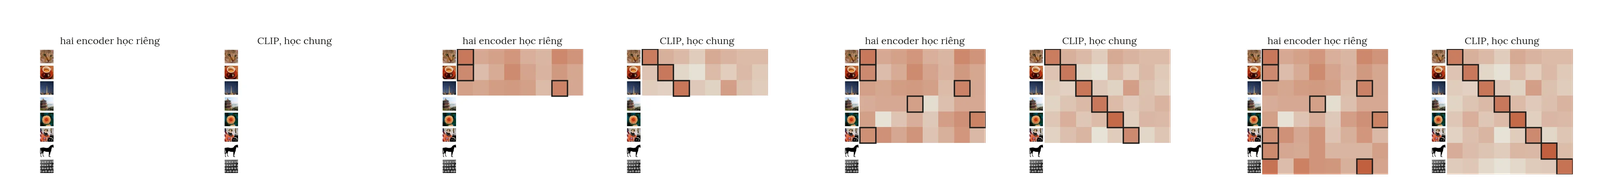

Phép chiếu tuyến tính đủ ở đây vì dữ liệu được dựng bằng phép xoay. Hai encoder thật có thể lệch nhau phi tuyến, nên projector thường là một MLP nhỏ (LLaVA-1.5 dùng MLP hai lớp), còn contrastive loss train cả hai encoder. Với vài nghìn cặp trong một đề thi, checkpoint đã căn chỉnh sẵn, nếu đề cho phép, thường là điểm xuất phát tốt hơn việc tự học căn chỉnh từ đầu.

**Hỏi nhanh.** Một đội lấy encoder ảnh và encoder chữ train riêng, cùng 512 chiều, rồi tính cosine trực tiếp để tìm ảnh cho 1000 câu. Mỗi câu có đúng một ảnh đúng trong 1000 ảnh. Recall@1 ra 0.001. Vì sao?

- A. Quên chuẩn hóa vector, chuẩn hóa xong sẽ ổn
- B. Đây là mức đoán bừa, vì hai hệ trục chưa được căn chỉnh
- C. 512 chiều quá ít, phải dùng encoder lớn hơn
- D. Phải dùng khoảng cách Euclid thay cho cosine

<details><summary>Đáp án</summary>

B. Đây là mức đoán bừa, vì hai hệ trục chưa được căn chỉnh

$1/1000 = 0.001$ là recall@1 của việc chọn bừa. Hai encoder train riêng không có tín hiệu nào buộc ảnh và câu đúng cặp phải nằm gần nhau. Chuẩn hóa chỉ đổi độ dài, không đổi hệ trục. Với vector đơn vị, Euclid và cosine xếp hạng như nhau. Encoder lớn hơn mà vẫn train riêng cũng không tự căn chỉnh được. Cần học căn chỉnh từ các cặp, hoặc dùng cặp encoder đã được train chung như CLIP.

</details>

**Hỏi nhanh.** Trong thí nghiệm, $W$ có $8\times 8 = 64$ số, và mỗi cặp cho 8 phương trình. Nếu chỉ có 8 cặp train thì sao?

- A. `lstsq` báo lỗi, vì không đủ phương trình
- B. Vẫn tốt như với 40 cặp, vì $W$ chỉ là một phép xoay
- C. Phải có ít nhất 64 cặp mới học được $W$
- D. $W$ khớp đúng 8 cặp train, kể cả phần nhiễu

<details><summary>Đáp án</summary>

D. $W$ khớp đúng 8 cặp train, kể cả phần nhiễu

8 cặp cho $8\times 8 = 64$ phương trình, vừa bằng 64 ẩn, nên least squares khớp tuyệt đối dữ liệu train, gồm cả nhiễu 0.3. Phần nhiễu ấy không lặp lại ở validation. Chạy lại code với 8 cặp đầu cho recall@1 bằng 0.35, so với 0.95 khi có 40 cặp. `lstsq` không báo lỗi, kể cả khi thiếu phương trình. Least squares không biết $W$ “nên” là một phép xoay, nên không dùng được ràng buộc ấy. 64 cặp là nhầm số phương trình với số cặp.

</details>

## VLM: hỏi đáp ảnh cần cả ảnh và câu hỏi

Vision-language model (VLM) nhận ảnh cùng chữ để tạo đáp án. Một cấu trúc phổ biến là image encoder, rồi projector, cho ra visual tokens; visual tokens cùng câu hỏi đi vào language model. [LLaVA](https://arxiv.org/abs/2304.08485) là một ví dụ theo hướng này.

Projector đổi chiều biểu diễn; nó không tự làm mọi vector ảnh có nghĩa nếu chưa được học đúng cặp. Ví dụ encoder ảnh trả vector 1024 chiều còn embedding của language model có 4096 chiều: projector tuyến tính là ma trận $1024 \times 4096$ cộng bias, khoảng 4.2 triệu tham số.



Có hai cách phổ biến để language model đọc ảnh:

- **Chèn visual tokens vào chuỗi đầu vào** (hình trên). Như LLaVA-1.5, ảnh $336\times336$ cắt thành patch $14\times14$ cho $24\times24=576$ visual tokens, nối với token câu hỏi, và self-attention của language model đọc tất cả. Cách này đơn giản nhưng tốn độ dài ngữ cảnh.
- **Cross-attention** (bài 6.5): giữ chuỗi chữ như cũ và chèn thêm các lớp cross-attention, query đến từ token chữ, key và value đến từ visual tokens, nên chữ “nhìn” được ảnh mà chuỗi không dài thêm; [Flamingo](https://arxiv.org/abs/2204.14198) theo hướng này. Cách này giữ chuỗi ngắn nhưng cần train các lớp mới chèn vào.

**Hỏi nhanh.** Câu hỏi có 40 token, còn ảnh cho 576 visual tokens. Nếu chèn visual tokens vào chuỗi, language model phải đọc một chuỗi dài bao nhiêu? Nếu dùng cross-attention từ chữ sang ảnh, ma trận điểm của một head có shape gì?

- A. Chuỗi 616 token, ma trận `(40, 576)`
- B. Chuỗi 616 token, ma trận `(576, 40)`
- C. Chuỗi 40 token, ma trận `(616, 616)`
- D. Chuỗi 576 token, ma trận `(40, 40)`

<details><summary>Đáp án</summary>

A. Chuỗi 616 token, ma trận `(40, 576)`

Chèn vào thì chuỗi gồm $40 + 576 = 616$ token. Với cross-attention, mỗi token chữ là một query, tức một hàng, chấm với mọi key từ ảnh, tức một cột, nên ma trận là `(40, 576)`. `(576, 40)` là đảo vai, ảnh đi hỏi chữ. `(616, 616)` là ma trận self-attention của cách chèn, không phải của cross-attention. 576 token là quên phần câu hỏi trong chuỗi. `(40, 40)` là self-attention giữa các token chữ.

</details>



Ảnh có ba quả bóng đỏ; câu “có mấy quả?” và “bóng màu gì?” dùng cùng ảnh nhưng cần output khác. Processor và template phải giữ đúng ảnh và câu hỏi, còn scorer quyết định đáp án là một số, một nhãn hay văn bản tự do. Crop có thể làm mất góc chứa vật cần đếm; OCR có thể đọc nhầm số phòng. Model lớn vẫn cần kiểm vùng ảnh và những trường hợp quan trọng với đề.

[Multimodal chat templates của Transformers](https://huggingface.co/docs/transformers/chat_templating_multimodal) giải thích cách processor gom nội dung chữ và ảnh rồi tạo tensor. Khi chạy model thật, dùng checkpoint có sẵn trên máy và template đi kèm, kiểm phiên bản thư viện có hỗ trợ kiến trúc, và decode đúng phần token mới (khác nhau giữa encoder–decoder và decoder-only). Ghi lại cấu hình resize, số visual tokens và giới hạn token sinh; đổi checkpoint thì đổi theo processor và template của chính checkpoint đó.

Phần kiểm được ngay trên CPU là **bộ đọc output**: một câu trả lời đẹp nhưng không đúng schema vẫn có thể làm file nộp lỗi. Ta thử bộ đọc trên ba chuỗi JSON đặt sẵn. Yêu cầu là đúng một khóa `count`, giá trị là integer không âm; `bool` phải bị loại dù Python coi nó là một loại `int`.

In [ ]:
import json

def parse_count(text):
    answer = json.loads(text)
    if not isinstance(answer, dict) or set(answer) != {"count"}:
        raise ValueError("cần đúng khóa count")
    count = answer["count"]
    if type(count) is not int or count < 0:
        raise ValueError("count phải là số nguyên không âm")
    return count

for response in ['{"count": 3}', '{"count": true}', '{"count": "3"}']:
    try:
        print(parse_count(response))
    except ValueError as error:
        print(str(error))

3
count phải là số nguyên không âm
count phải là số nguyên không âm


Parser nhận 3 ở trường hợp đầu, từ chối boolean và chuỗi. Nó chỉ kiểm định dạng, không chứng minh ảnh có đúng ba bóng. Phải chấm nội dung trên reference và định nghĩa fallback nếu generation sai schema. Một prompt yêu cầu JSON không thay thế validation bằng code.

**Hỏi nhanh.** Parser `parse_count` ở trên nhận chuỗi nào?

- A. `{"count": 3.0}`
- B. `{'count': 3}`
- C. `{ "count" : 3 }`
- D. `{"count": 3, "unit": "qua"}`

<details><summary>Đáp án</summary>

C. `{ "count" : 3 }`

JSON cho phép khoảng trắng quanh dấu `:`, nên `{ "count" : 3 }` đọc ra đúng một dict có một khóa, với giá trị integer 3. `3.0` là `float`, nên bị chặn bởi `type(count) is not int`. Nháy đơn không phải JSON hợp lệ. `json.loads` ném `JSONDecodeError`, một lớp con của `ValueError`, nên vòng `try` trong bài vẫn bắt được. Khóa thừa `unit` làm tập khóa khác với `{"count"}`.

</details>

## Khi đi thi

- **Lập bảng ablation trước khi ghép phức tạp.** Từng nhánh riêng, late fusion có trọng số, early fusion, trên cùng split và metric; ghi cả thời gian chạy và bộ nhớ của mỗi dòng.
- **Kiểm cặp ngay khi đọc dữ liệu.** Join theo ID, đếm ID thiếu và trùng; với audio, video, đổi chỉ số frame về giây rồi xem, nghe thử vài mẫu đã ghép.
- **Mô phỏng thiếu nguồn đúng như đề mô tả.** Nếu test có thể mất audio hay caption, bỏ đúng tỉ lệ đó trên validation, thêm cờ availability và quy định fallback khi thiếu hết.
- **Tính chi phí từng nhánh trước khi chạy cả tập.** Số visual tokens, thời gian encode audio, video và độ dài sinh; một nhánh thêm chút điểm mà làm vượt giới hạn thời gian là nhánh lỗ.
- **Kiểm file nộp bằng code, khóa cấu hình trước test.** Parser schema và fallback khi model sinh sai định dạng; khóa trọng số fusion, prompt, checkpoint trước khi chạy test, chỉ dùng dữ liệu và checkpoint đề cho phép.

## Tóm tắt

- Ghép đúng mẫu theo ID và theo thời gian là điều kiện đầu tiên; shape đúng chưa bảo đảm cặp đúng.
- Early fusion nối đặc trưng, nhưng linear head chỉ cộng điểm riêng từng nguồn; tương tác cần MLP, đặc trưng tích hoặc gating. Late fusion gộp dự đoán cùng lớp, trọng số chọn trên validation.
- Ablation (từng nhánh, phá cặp, mất nguồn) đo đóng góp thật; thêm modality không bảo đảm tăng điểm.
- Vector cùng chiều chưa cùng hệ trục; căn chỉnh phải học từ các cặp.
- VLM đọc ảnh bằng visual tokens chèn vào chuỗi hoặc qua cross-attention; schema đúng và nội dung đúng là hai kiểm tra riêng.

## Kiểm tra cuối bài

**Câu 1.** Bài toán nào là đa phương thức thật sự?

- A. Đoán thể loại của clip từ khung hình, âm thanh và phụ đề
- B. Phân loại tiếng chim bằng cách vẽ audio thành spectrogram rồi đưa vào CNN
- C. Phân loại cảm xúc của bình luận, kèm bản dịch máy của bình luận ấy
- D. Phân loại ảnh, ghép ảnh gốc với năm bản augmentation của nó

<details><summary>Đáp án</summary>

A. Đoán thể loại của clip từ khung hình, âm thanh và phụ đề

Model đa phương thức xử lý nhiều loại dữ liệu khác nhau của cùng một mẫu, ở đây là ảnh, âm thanh và chữ. Spectrogram là một cách biểu diễn audio dưới dạng mảng 2D. Dùng CNN ảnh không biến nguồn thành ảnh, dữ liệu vẫn chỉ là âm thanh. Bản dịch máy vẫn là chữ, lại còn sinh ra từ chính bình luận. Augmentation chỉ tạo thêm biến thể của cùng một ảnh.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 257](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=92)

</details>

**Câu 2.** Ba nhánh có trọng số đều cho xác suất lớp 1 là 0.99, 0.2 và 0.2, với ngưỡng 0.5. Lấy trung bình xác suất, và lấy trung bình logit rồi qua sigmoid, mỗi cách dự đoán lớp nào?

- A. Cả hai cách đều dự đoán lớp 1
- B. Trung bình xác suất cho lớp 0, trung bình logit cho lớp 1
- C. Trung bình xác suất cho lớp 1, trung bình logit cho lớp 0
- D. Cả hai cách đều dự đoán lớp 0

<details><summary>Đáp án</summary>

B. Trung bình xác suất cho lớp 0, trung bình logit cho lớp 1

Trung bình xác suất là $(0.99 + 0.2 + 0.2)/3 \approx 0.463 < 0.5$, nên ra lớp 0. Về logit, $\ln(0.99/0.01) \approx 4.60$, còn $\ln(0.2/0.8) \approx -1.39$ hai lần. Trung bình khoảng 0.61, qua sigmoid khoảng 0.65, nên ra lớp 1. Logit không bị chặn, nên một nhánh rất tự tin kéo mạnh. Xác suất bị chặn ở 1, nên một nhánh không lấn được hai nhánh kia. Với hai nhánh có trọng số đều, hai cách luôn cùng quyết định ở ngưỡng 0.5. Khác biệt chỉ lộ ra từ ba nhánh trở lên, hoặc khi trọng số lệch nhau. Cách nào tốt hơn là do validation quyết định.

</details>

**Câu 3.** Nhánh ảnh có `classes=[xe, chuông]`, `p=[0.8, 0.2]`. Nhánh chữ có `classes=[chuông, xe]`, `p=[0.7, 0.3]`. Gộp đều sau khi căn đúng thứ tự lớp, xác suất của “xe” là bao nhiêu?

- A. 0.25
- B. 0.45
- C. 0.55
- D. 0.75

<details><summary>Đáp án</summary>

C. 0.55

Xác suất “xe” ở nhánh chữ là 0.3, nên gộp lại được $(0.8 + 0.3)/2 = 0.55$. 0.75 là cộng thẳng cột 0 của hai nhánh, trộn “xe” với “chuông”. 0.45 là xác suất của “chuông” sau khi căn chỉnh, $(0.2 + 0.7)/2$. 0.25 là ghép “chuông” của ảnh với “xe” của chữ.

</details>

**Câu 4.** Một VLM đạt accuracy 0.71 trên validation hỏi đáp ảnh. Thay mọi ảnh bằng một ảnh xám trống, giữ nguyên câu hỏi, thì được 0.66. Phần lớn câu hỏi là có/không hoặc đếm. Ta kết luận được gì?

- A. Model dùng ảnh tốt, vì 0.66 vẫn thấp hơn 0.71
- B. Ảnh xám làm hỏng processor, nên số 0.66 vô nghĩa
- C. Nên bỏ hẳn nhánh ảnh để inference nhanh hơn
- D. Câu hỏi tự để lộ phần lớn đáp án, còn ảnh góp ít

<details><summary>Đáp án</summary>

D. Câu hỏi tự để lộ phần lớn đáp án, còn ảnh góp ít

VLM phải đọc ảnh và câu hỏi cùng lúc. Baseline “mù” đo phần đáp án đoán được chỉ từ câu hỏi, chẳng hạn trả lời “có”, hoặc trả một số đếm phổ biến. 0.66 so với 0.71 nghĩa là phần lớn điểm không cần nhìn ảnh. Bước tiếp theo là đọc lỗi theo từng loại câu hỏi, và dựng một validation mà câu hỏi không để lộ đáp án. Ảnh xám vẫn là input hợp lệ. Nếu nghi ngờ, hãy xem vài mẫu sau processor. Bỏ ảnh thì mất 5 điểm, và mất đúng những câu thật sự cần nhìn.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 264](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=94)

</details>

**Câu 5.** Một đội có 2 triệu ảnh không chú thích và 2 triệu đoạn tin tức, hai kho không liên quan đến nhau. Đội muốn train từ đầu hai encoder ảnh và chữ trong cùng một không gian, để tìm ảnh bằng câu. Trở ngại chính là gì?

- A. Không có cặp ghép nào, nên không có gì để căn chỉnh
- B. Dữ liệu quá ít so với pretraining chỉ có chữ
- C. Hai encoder phải có cùng số chiều ngay từ đầu
- D. Ảnh và chữ phải dùng chung tokenizer mới so được

<details><summary>Đáp án</summary>

A. Không có cặp ghép nào, nên không có gì để căn chỉnh

Căn chỉnh được học từ quan hệ cặp. Trong thí nghiệm của bài, học $W$ từ những cặp bị xáo cho recall@1 bằng 0.00. Mỗi kho có thể tự học biểu diễn riêng, nhưng không có gì cho biết ảnh nào ứng với câu nào. Thu thập cặp ở quy mô lớn mới là phần khó của pretraining ảnh–chữ. Hai triệu mẫu mỗi bên không phải là ít. Số chiều chỉnh được bằng một phép chiếu. Tokenizer chỉ dùng cho chữ.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 266](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=95)

</details>

**Câu 6.** Một model phân loại cảm xúc cuộc gọi cho transcript đọc audio qua cross-attention. Query lấy từ 40 token transcript, key và value lấy từ 100 frame audio, và kết quả được cộng vào residual của transcript. Khoảng 10% cuộc gọi ở test bị mất audio. Với chúng, `has_frame` toàn `False`, và đoạn code dưới đây cho `weights` toàn NaN.
```py
scores = scores.masked_fill(~has_frame[:, None, :], float("-inf"))
weights = scores.softmax(dim=-1)
```
Xử lý những cuộc gọi mất audio thế nào cho đúng?

- A. Điền 0 cho mọi frame audio và bỏ mask, để attention đọc như thường
- B. Thay `-inf` bằng `-1e9` để softmax chia đều cho 100 frame
- C. Bỏ các cuộc gọi mất audio khỏi file dự đoán, chỉ nộp phần còn lại
- D. Đặt cổng của cross-attention về 0, giữ residual, và thêm cờ availability

<details><summary>Đáp án</summary>

D. Đặt cổng của cross-attention về 0, giữ residual, và thêm cờ availability

Hàng điểm toàn $-\infty$ khiến softmax ra $0/0$. Cuộc gọi không có frame nào thì không có gì để đọc, nên nhánh cross-attention phải tắt cho mẫu đó. Cổng bằng 0 bỏ phần cộng vào residual, nên transcript đi tiếp như một model chỉ có chữ, còn cờ availability cho head biết audio đang vắng. Khi train, dùng modality dropout, tức ngẫu nhiên tắt audio ở một phần mẫu, để model quen với trường hợp này. Điền 0 rồi bỏ mask, hay thay bằng `-1e9`, đều hết NaN, nhưng cho trọng số đều $1/100$ trên những frame giả. Với audio bằng 0, transcript nhận đúng bias của phép chiếu value, tức một “âm thanh” cố định mà model chưa từng thấy khi train, và không phân biệt được với audio thật. `-1e9` còn tràn số khi chạy fp16. File dự đoán phải có đủ mọi cuộc gọi trong test, nên không bỏ được 10% ấy.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 265](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=95)

</details>

**Câu 7.** Lúc train thì luôn có đủ ảnh và audio. Đề báo khoảng 30% clip test bị mất audio, và pipeline điền vector 0 cho audio thiếu. Validation có đủ nguồn đạt 0.90, nhưng điểm public test chỉ 0.74. Nên làm gì trước tiên?

- A. Train thêm epoch để nhánh audio đủ mạnh hơn
- B. Mô phỏng 30% mất audio ở validation và cả lúc train
- C. Tăng trọng số của nhánh audio lúc gộp hai nhánh
- D. Bỏ nhánh audio khỏi mọi clip, cả lúc train lẫn lúc test

<details><summary>Đáp án</summary>

B. Mô phỏng 30% mất audio ở validation và cả lúc train

Model chưa từng thấy “audio bằng 0” khi train. Sau chuẩn hóa, vector 0 có thể trông như một âm thanh hợp lệ. Validation có đủ nguồn thì không giống test, nên không báo trước được điểm sẽ rơi. Hãy mô phỏng đúng tỉ lệ thiếu trên validation để đo, rồi thêm cờ availability và modality dropout khi train để model học cách xử lý. Train thêm hay tăng trọng số audio đều không chạm tới chỗ thiếu. Bỏ hẳn audio là một baseline đáng so, nhưng mất thông tin ở 70% clip còn audio.

</details>

**Câu 8.** Early fusion nối embedding ảnh, với giá trị cỡ $\pm 1$, với 20 đặc trưng audio thô, trong đó cột năng lượng có giá trị cỡ hàng nghìn, rồi train MLP bằng SGD. Loss dao động mạnh và gần như không giảm. Nên sửa gì trước?

- A. Chuẩn hóa từng cột bằng mean và std tính trên train
- B. Giảm số chiều của embedding ảnh cho cân bằng với audio
- C. Nhân embedding ảnh với 1000 cho cùng thang đo với audio
- D. Bỏ cột năng lượng, vì giá trị của nó quá lớn

<details><summary>Đáp án</summary>

A. Chuẩn hóa từng cột bằng mean và std tính trên train

Cột có giá trị lớn tạo gradient lớn cho các trọng số nối với nó. Learning rate vừa với cột này thì lại quá nhỏ cho các cột khác, nên mặt loss thành một thung lũng dài và hẹp. Chuẩn hóa bằng thống kê của train đưa các cột về cùng thang mà vẫn giữ thông tin. Nhân ảnh với 1000 phá thang của embedding, mà các cột audio vẫn lệch nhau. Bỏ cột năng lượng là mất thông tin. Giảm số chiều ảnh không đụng tới thang đo.

</details>

**Câu 9.** Với late fusion, đội dò $\alpha$ trên lưới $0, 0.01, \dots, 1$ bằng 60 mẫu validation. $\alpha = 0.37$ đạt 0.95, $\alpha = 0.5$ đạt 0.90, còn nhánh riêng tốt nhất đạt 0.88. Đội báo “fusion tăng 7 điểm”. Báo cáo này có vấn đề gì?

- A. Không có vấn đề, vì validation là nơi đúng để dò $\alpha$
- B. 0.95 đo trên chính 60 mẫu đã dùng để chọn $\alpha$
- C. Phải dò $\alpha$ trên test, vì test là mục tiêu cuối cùng
- D. Lưới quá thô, phải dò với bước 0.001 cho chắc

<details><summary>Đáp án</summary>

B. 0.95 đo trên chính 60 mẫu đã dùng để chọn $\alpha$

Validation là nơi đúng để dò, nhưng điểm tốt nhất trong 101 lần thử trên cùng 60 mẫu không còn là một ước lượng sạch. Một mẫu đã là 1.7 điểm, và giá trị được chọn khớp cả phần dao động của chính 60 mẫu này. Muốn ước lượng trung thực, hãy dùng cross-validation, tức dò $\alpha$ trong từng fold rồi đo trên fold còn lại, hoặc giữ riêng một phần held-out. Test không dùng để chọn. Lưới mịn hơn còn làm số đo lạc quan hơn nữa.

</details>

**Câu 10.** Một VLM đếm người trong ảnh toàn cảnh có tỉ lệ 4:1. Processor resize cạnh ngắn về 336 rồi center crop $336\times 336$. Model thường đếm thiếu những người đứng ở hai đầu ảnh. Nguyên nhân khả dĩ nhất là gì?

- A. Language model chưa hiểu được loại câu hỏi đếm
- B. Parser đọc sai số đếm trong chuỗi JSON đầu ra
- C. 336 pixel quá nhỏ để model nhìn thấy người
- D. Center crop chỉ giữ lại 1/4 chiều ngang của ảnh

<details><summary>Đáp án</summary>

D. Center crop chỉ giữ lại 1/4 chiều ngang của ảnh

Ảnh 4:1 sau khi resize thành $1344\times 336$. Crop $336\times 336$ ở giữa chỉ giữ 1/4 bề ngang, nên người ở hai đầu không bao giờ vào được model. Lỗi có hệ thống theo vị trí thì trỏ về vùng ảnh, không phải phần hiểu câu hỏi hay parser. 336 pixel có thể làm người ở xa mờ đi, nhưng không giải thích được việc chỉ sai ở hai đầu. Hãy kiểm bằng cách lưu ảnh sau processor ra xem. Sửa bằng cách pad về hình vuông, hoặc cắt ảnh thành nhiều ô rồi cộng số đếm, cẩn thận với người đứng đúng chỗ cắt.

</details>

## Đọc thêm

- Baltrušaitis, Ahuja, Morency — [*Multimodal Machine Learning: A Survey and Taxonomy*](https://arxiv.org/abs/1705.09406). Đọc mối liên hệ giữa representation, alignment và fusion.
- Radford và cộng sự — [*Learning Transferable Visual Models From Natural Language Supervision*](https://arxiv.org/abs/2103.00020). Đọc paired contrastive learning và zero-shot của CLIP.
- Liu và cộng sự — [*Visual Instruction Tuning*](https://arxiv.org/abs/2304.08485). Xem cách chèn visual tokens qua projector và hai giai đoạn train của LLaVA.
- Alayrac và cộng sự — [*Flamingo: a Visual Language Model for Few-Shot Learning*](https://arxiv.org/abs/2204.14198). Xem cách chèn lớp cross-attention vào language model đã đóng băng.
- Transformers — [Multimodal chat templates](https://huggingface.co/docs/transformers/chat_templating_multimodal). Tra processor, nội dung message và template trước khi chạy checkpoint VLM thật.

Nguồn ảnh: ảnh `chelsea`, `coffee`, `rocket`, `astronaut`, `horse`, `coins` kèm scikit-image (CC0 hoặc public domain); ảnh tháp là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0); ảnh hoa là ảnh mẫu `flower.jpg` kèm scikit-learn (vultilion, Flickr, CC BY 2.0).